# Battery SOH — Simple Baselines, Feature Sufficiency & Robustness Study

**Research question:** Are complex temporal networks actually necessary for estimating current-cycle SOH from the five selected CALCE CX2 charging features? If not, can we identify a more useful problem (missing indicators, robustness, cell shift, or data quality)?

This is an **experimental investigation**, not a claim of innovation. It compares ordinary linear regression, Ridge, XGBoost (with a scikit-learn fallback), a small neural MLP and a causal Transformer on **identical prediction targets**. It also audits target fluctuations, tests the incremental value of the five features and evaluates missing-feature robustness.

### Study design and safeguards

- **Task:** current-cycle SOH estimation using features measured during that same cycle. This is **not next-cycle forecasting**.
- **Training:** `train_final_filtered.csv` (experimental threshold filtering). **Validation:** `validation.csv`. **Held-out reporting:** `test.csv`, unchanged. Preprocessing uses training data only.
- **Fair sample matching:** all four models use exactly the **same final-cycle targets** from 12-cycle uninterrupted windows. Tabular models see only the final cycle's features; Transformer also sees preceding features. This tests the value of history, not model capacity alone.
- **Model selection:** use validation results, **never tune against the repeatedly inspected CX2_38 test battery**. Treat test comparisons as descriptive. A new external set is needed for pristine confirmatory testing.
- **Data quality:** flags and audits do not prove that a measured SOH jump is invalid; no labels are silently smoothed or overwritten.
- **Outputs:** tables, sample-aligned predictions, plots, saved models, parameters, and a gap-analysis summary.

A fresh LOBO fold option is included for **exploratory** comparison across batteries. Use inner validation only to choose epochs, not held-out folds.

In [1]:
# Run this cell once if dependencies are missing, then restart the kernel if needed.
# %pip install numpy pandas matplotlib scikit-learn torch xgboost joblib

In [2]:
from pathlib import Path
import json, time, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

try:
    from xgboost import XGBRegressor
    HAVE_XGBOOST = True
except ImportError:
    HAVE_XGBOOST = False
    print('XGBoost not installed. Falling back to sklearn HistGradientBoostingRegressor.')

DATA_DIR = Path(r'C:\Projects\Battery_Soh\pre processed ready to use data')
TRAIN_NAME = 'train_final_filtered.csv'       # Do not silently fall back to original train.csv
OUTPUT_DIR = Path('soh_research_gap_benchmark')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
TARGET = 'soh'
SEQ_LEN = 12
SEEDS = (42,123,2026)
EPOCHS = 80
PATIENCE = 12
BATCH_SIZE = 128
LR = 1e-3
WEIGHT_DECAY = 1e-4
HIDDEN = 64
XGB_ESTIMATORS = 350
MAX_TRAIN_BATCHES = None   # None for full run; set 2 for a syntax smoke test
RUN_FEATURE_ABLATIONS = True
RUN_MISSINGNESS_STRESS = True
RUN_FILTER_SENSITIVITY = True
RUN_LOBO = False           # Turn on after main notebook; exploratory, not pristine holdout evidence
RUN_LOBO_TRANSFORMER = False  # Adds neural training per fold; more expensive
LOBO_FOLDS = 'full'        # 'pilot' or 'full'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| Torch:', torch.__version__, '| XGBoost available:', HAVE_XGBOOST)

XGBoost not installed. Falling back to sklearn HistGradientBoostingRegressor.
Device: cuda | Torch: 2.11.0+cu128 | XGBoost available: False


In [3]:
# Explicitly require the user-generated filtered file; never silently change the experiment.
required = [DATA_DIR/TRAIN_NAME, DATA_DIR/'train.csv', DATA_DIR/'validation.csv', DATA_DIR/'test.csv']
missing = [str(p) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError('Missing required file(s): ' + str(missing) +
                            '. Set DATA_DIR or generate train_final_filtered.csv first.')

def load_frame(path):
    f = pd.read_csv(path)
    need = set(FEATURES + [TARGET,'battery','cycle_ordinal'])
    if not need.issubset(f.columns):
        raise ValueError(f'{path}: missing {need-set(f.columns)}')
    if f[FEATURES+[TARGET,'cycle_ordinal']].isna().any().any():
        raise ValueError(f'{path}: missing required numerical values')
    if f.duplicated(['battery','cycle_ordinal']).any():
        raise ValueError(f'{path}: repeated battery/cycle_ordinal keys')
    return f.sort_values(['battery','cycle_ordinal']).reset_index(drop=True)

original_train = load_frame(DATA_DIR/'train.csv')
splits = {
 'train':load_frame(DATA_DIR/TRAIN_NAME),
 'validation':load_frame(DATA_DIR/'validation.csv'),
 'test':load_frame(DATA_DIR/'test.csv')}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert set(splits[a].battery).isdisjoint(set(splits[b].battery)), 'Battery leakage!'

# Verify filtered rows are a subset of the original based on physical sample ID.
orig_keys = set(zip(original_train.battery,original_train.cycle_ordinal))
flt_keys = set(zip(splits['train'].battery,splits['train'].cycle_ordinal))
assert flt_keys.issubset(orig_keys), 'Filtered training contains unknown cycles.'
assert len(splits['train']) <= len(original_train)

print('Data:', DATA_DIR)
for name,frame in splits.items():
    print(f'{name:>10}: {len(frame):>5} cycles, batteries = {sorted(frame.battery.unique())}')
print('Training-only records excluded:',len(original_train)-len(splits['train']))

mu = splits['train'][FEATURES].mean().to_numpy(dtype=np.float32)
sigma = splits['train'][FEATURES].std(ddof=0).to_numpy(dtype=np.float32)
sigma = np.where(sigma < 1e-8, 1., sigma)
(OUTPUT_DIR/'scaler.json').write_text(json.dumps({'features':FEATURES,'mean':mu.tolist(),
    'std':sigma.tolist(),'fit_split':'train_final_filtered.csv'},indent=2))

Data: C:\Projects\Battery_Soh\pre processed ready to use data
     train:  7690 cycles, batteries = ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation:  1743 cycles, batteries = ['CX2_36']
      test:  1477 cycles, batteries = ['CX2_38']
Training-only records excluded: 100


431

## 1 — Same-cycle evaluation windows for every model

A window of 12 consecutive cycle ordinals ends at cycle *k*. The label is **SOH at cycle k**. A classical regressor uses the five features from cycle *k* only; the Transformer uses cycles *k−11 ... k*. We never connect windows across missing or removed cycles. All predictions are compared on the exact same `battery + cycle_ordinal` rows.

In [4]:
def make_windows(frame, mean, std, seq_len=SEQ_LEN):
    x, y, meta = [], [], []
    for bat, g in frame.groupby('battery',sort=True):
        g = g.sort_values('cycle_ordinal').reset_index(drop=True)
        ords = g.cycle_ordinal.to_numpy()
        bounds = np.r_[0,np.where(np.diff(ords)!=1)[0]+1,len(g)]
        for lo,hi in zip(bounds[:-1],bounds[1:]):
            p = g.iloc[lo:hi]
            if len(p) < seq_len: continue
            z = (p[FEATURES].to_numpy(dtype=np.float32) - mean) / std
            t = p[TARGET].to_numpy(dtype=np.float32)
            for j in range(seq_len-1,len(p)):
                x.append(z[j-seq_len+1:j+1])
                y.append(t[j])
                row = p.iloc[j]
                meta.append({'battery':str(bat),'cycle_ordinal':int(row.cycle_ordinal),
                             'actual_soh':float(t[j])})
    if not x: raise ValueError('No eligible windows. Check cycle gaps and SEQ_LEN.')
    return {'X':np.asarray(x,dtype=np.float32),
            'y':np.asarray(y,dtype=np.float32),
            'meta':pd.DataFrame(meta)}

windows = {name:make_windows(df,mu,sigma) for name,df in splits.items()}
for name,d in windows.items():
    print(name, 'eligible windows',len(d['y']), '| lost due to history/gaps',len(splits[name])-len(d['y']))
    assert len(d['X'])==len(d['y'])==len(d['meta'])

def evaluate_numbers(y,p):
    y = np.asarray(y,dtype=float).ravel(); p = np.asarray(p,dtype=float).ravel()
    return {'RMSE':float(np.sqrt(np.mean((p-y)**2))),
            'MAE':float(np.mean(np.abs(p-y))),
            'MAPE_pct':float(100*np.mean(np.abs(p-y)/np.maximum(np.abs(y),1e-8))),
            'R2':float(r2_score(y,p)) if len(y)>1 else float('nan'),
            'MBE':float(np.mean(p-y))}

def write_predictions(split,name,seed,p,win=windows,extra=''):
    f=win[split]['meta'].copy()
    f['predicted_soh']=np.asarray(p)
    f['signed_error']=f['predicted_soh']-f['actual_soh']
    f.to_csv(OUTPUT_DIR/f'{extra}{name}_seed{seed}_{split}_predictions.csv',index=False)

train eligible windows 3869 | lost due to history/gaps 3821
validation eligible windows 918 | lost due to history/gaps 825
test eligible windows 752 | lost due to history/gaps 725


## 2 — Audit the abrupt changes, without altering measurements

Large step changes are **quality flags**, not proof of incorrect measurements. Report prevalence by battery and evaluate whether the threshold-filtered training set still contains long sawtooth segments. This code does not drop validation or test observations.

,n,jump_count,minimum_soh,maximum_soh,jump_rate_pct
battery,,,,,
CX2_16,1899,47,0.593,0.943,2.475
CX2_33,1488,1,0.473,0.960,0.067
CX2_34,1554,2,0.481,1.004,0.129
CX2_35,1630,0,0.443,1.012,0.000
CX2_36,1743,1,0.469,1.008,0.057
CX2_37,1219,0,0.607,1.012,0.000
CX2_38,1477,1,0.472,1.009,0.068


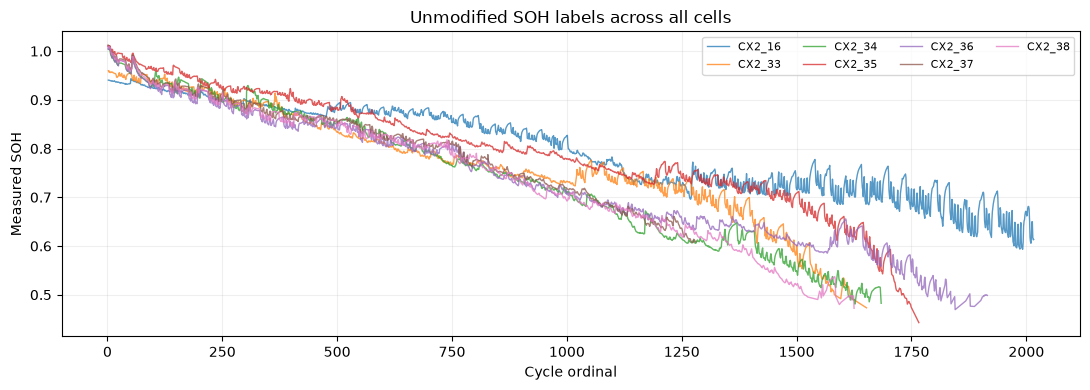

In [5]:
def change_audit(frame, threshold=0.03):
    f=frame.sort_values(['battery','cycle_ordinal']).copy()
    grp=f.groupby('battery')
    f['delta_soh']=grp['soh'].diff()
    f['cycle_gap']=grp['cycle_ordinal'].diff()
    f['large_jump']=(f.cycle_gap==1)&(f.delta_soh.abs()>threshold)
    return f

full_original=pd.concat([original_train,splits['validation'],splits['test']],ignore_index=True)
audit=change_audit(full_original)
audit.to_csv(OUTPUT_DIR/'soh_jump_audit.csv',index=False)
quality=(audit.groupby('battery').agg(n=('soh','size'),jump_count=('large_jump','sum'),
    minimum_soh=('soh','min'),maximum_soh=('soh','max')))
quality['jump_rate_pct']=100*quality.jump_count/quality.n
quality.to_csv(OUTPUT_DIR/'soh_quality_summary.csv')
display(quality.round(3))
fig,ax=plt.subplots(figsize=(11,4))
for b,g in audit.groupby('battery'):
    ax.plot(g.cycle_ordinal,g.soh,label=b,alpha=.75,lw=1)
ax.set(xlabel='Cycle ordinal',ylabel='Measured SOH',title='Unmodified SOH labels across all cells')
ax.grid(alpha=.2);ax.legend(ncol=4,fontsize=8)
fig.tight_layout();fig.savefig(OUTPUT_DIR/'soh_raw_all_cells.png',dpi=160)
plt.show()

## 3 — Establish simple and neural reference models

- **Ridge**: linear predictor; a crucial control for the CC-duration/SOH correlation.
- **XGBoost**: strong tabular nonlinear baseline; falls back to scikit-learn's HistGradientBoosting when not installed.
- **MLP**: a small nonlinear feedforward neural network using the same current-cycle features.
- **Transformer**: causal 12-cycle architecture matching our earlier five-model benchmark as closely as possible.

The *MLP* and *Transformer* use identical optimizer/early-stopping logic. OLS, Ridge and boosted trees have fixed hyperparameters, not tuned on test.

In [6]:
class PerStepMLP(nn.Module):
    def __init__(self, dim=5, hidden=64):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(dim,hidden),nn.ReLU(),
                nn.Linear(hidden,hidden),nn.ReLU(),nn.Linear(hidden,1))
    def forward(self,x):
        return self.net(x[:,-1,:]).squeeze(-1)

class TransformerModel(nn.Module):
    def __init__(self,dim=5,hidden=64,nhead=4,layers=2,max_len=512):
        super().__init__()
        self.input=nn.Linear(dim,hidden)
        self.pos=nn.Embedding(max_len,hidden)
        enc=nn.TransformerEncoderLayer(d_model=hidden,nhead=nhead,
              dim_feedforward=hidden*2,dropout=.1,batch_first=True,activation='gelu')
        self.encoder=nn.TransformerEncoder(enc,num_layers=layers,enable_nested_tensor=False)
        self.head=nn.Linear(hidden,1)
    def forward(self,x):
        t=x.shape[1]
        z=self.input(x)+self.pos(torch.arange(t,device=x.device))[None,:,:]
        attn_mask=torch.triu(torch.ones(t,t,device=x.device,dtype=torch.bool),diagonal=1)
        z=self.encoder(z,mask=attn_mask)
        return self.head(z[:,-1,:]).squeeze(-1)

def build_tree(seed):
    if HAVE_XGBOOST:
        return XGBRegressor(n_estimators=XGB_ESTIMATORS,max_depth=3,learning_rate=.05,
                  subsample=.85,colsample_bytree=1.,objective='reg:squarederror',
                  reg_lambda=2.,random_state=seed,n_jobs=4,tree_method='hist')
    return HistGradientBoostingRegressor(max_iter=220,max_depth=3,learning_rate=.05,
                 l2_regularization=2.,random_state=seed)

def set_seed(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def loaders(train,val,seed):
    g=torch.Generator().manual_seed(seed)
    tr=DataLoader(TensorDataset(torch.from_numpy(train['X']),torch.from_numpy(train['y'])),
         batch_size=BATCH_SIZE,shuffle=True,generator=g,num_workers=0)
    va=DataLoader(TensorDataset(torch.from_numpy(val['X']),torch.from_numpy(val['y'])),
         batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
    return tr,va

@torch.no_grad()
def predict_torch(model,X,batch_size=1024):
    model.eval()
    parts=[]
    for j in range(0,len(X),batch_size):
        pred=model(torch.from_numpy(X[j:j+batch_size]).to(DEVICE))
        parts.append(pred.detach().cpu().numpy())
    return np.concatenate(parts)

def train_neural(kind,train,val,seed,epochs=None,output_prefix=None):
    set_seed(seed)
    model = (PerStepMLP(len(FEATURES),HIDDEN) if kind=='mlp' else
             TransformerModel(len(FEATURES),HIDDEN)).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    tr_loader,va_loader=loaders(train,val,seed)
    epochs = EPOCHS if epochs is None else epochs
    best_val=float('inf');best_state=None;stale=0;history=[]
    start=time.perf_counter()
    for epoch in range(1,epochs+1):
        model.train();sumloss=0.;count=0
        for bi,(xb,yb) in enumerate(tr_loader):
            if MAX_TRAIN_BATCHES is not None and bi>=MAX_TRAIN_BATCHES: break
            xb=xb.to(DEVICE);yb=yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            pred=model(xb);loss=((pred-yb)**2).mean()
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.)
            opt.step();sumloss+=float(loss.detach())*len(yb);count+=len(yb)
        if count==0: raise RuntimeError('MAX_TRAIN_BATCHES prevents training.')
        vp=predict_torch(model,val['X'])
        vr=float(np.sqrt(np.mean((vp-val['y'])**2)))
        history.append({'epoch':epoch,'train_MSE':sumloss/count,'val_RMSE':vr})
        if vr < best_val-1e-7:
            best_val=vr;best_state=copy.deepcopy(model.state_dict());stale=0
        else:
            stale+=1
            if stale>=PATIENCE:break
    model.load_state_dict(best_state)
    elapsed=time.perf_counter()-start
    if output_prefix:
        torch.save({'model':kind,'state_dict':model.state_dict(),'features':FEATURES,
                    'seq_len':SEQ_LEN,'seed':seed},OUTPUT_DIR/f'{output_prefix}.pt')
        pd.DataFrame(history).to_csv(OUTPUT_DIR/f'{output_prefix}_history.csv',index=False)
    return model,{'seconds':elapsed,'epochs':len(history),'parameters':sum(p.numel() for p in model.parameters())}

## 4 — Main matched benchmark (filtered training, original validation/test)

**Run this cell to train the models.** Neural model checkpoints use **validation-based early stopping**, and test performance is reported afterward. Because CX2_38 has already been inspected repeatedly in prior experiments, **do not use its score to decide new hyperparameters or claim independent confirmation**.

In [7]:
all_metrics=[]
trained_models={}
for model_name in ['ols','ridge','xgboost' if HAVE_XGBOOST else 'hist_gradient_boosting','mlp','transformer']:
    seeds = (SEEDS[0],) if model_name in ('ols','ridge') else SEEDS
    for seed in seeds:
        start=time.perf_counter()
        if model_name in ('ols','ridge'):
            model=(LinearRegression() if model_name=='ols' else Ridge(alpha=1.0)).fit(windows['train']['X'][:,-1,:],windows['train']['y'])
            info={'seconds':time.perf_counter()-start,'epochs':0,
                  'parameters':len(model.coef_)+1}
            joblib.dump(model,OUTPUT_DIR/f'{model_name}_seed{seed}.joblib')
        elif model_name in ('xgboost','hist_gradient_boosting'):
            model=build_tree(seed)
            model.fit(windows['train']['X'][:,-1,:],windows['train']['y'])
            info={'seconds':time.perf_counter()-start,'epochs':0,'parameters':None}
            joblib.dump(model,OUTPUT_DIR/f'{model_name}_seed{seed}.joblib')
        else:
            model,info=train_neural(model_name,windows['train'],windows['validation'],seed,
                              output_prefix=f'{model_name}_seed{seed}')
        trained_models[(model_name,seed)]=model
        for split in ['validation','test']:
            X=windows[split]['X']
            p=(predict_torch(model,X) if isinstance(model,nn.Module)
               else model.predict(X[:,-1,:]))
            all_metrics.append({'split':split,'model':model_name,'seed':seed,
                 'n':len(p),'train_seconds':info['seconds'],
                 'epochs':info['epochs'],'parameters':info['parameters'],
                 **evaluate_numbers(windows[split]['y'],p)})
            write_predictions(split,model_name,seed,p)
        print(f'Finished {model_name}, seed={seed}, validation RMSE=',
              f'{all_metrics[-2]["RMSE"]:.6f}')

metrics_df=pd.DataFrame(all_metrics)
metrics_df.to_csv(OUTPUT_DIR/'metrics_all_runs.csv',index=False)
summary=(metrics_df.groupby(['split','model']).agg(
    RMSE_mean=('RMSE','mean'),RMSE_std=('RMSE','std'),MAE_mean=('MAE','mean'),
    MAPE_mean=('MAPE_pct','mean'),R2_mean=('R2','mean'),
    n_seeds=('seed','nunique'),train_seconds_mean=('train_seconds','mean'))
    .reset_index())
summary.to_csv(OUTPUT_DIR/'metrics_summary.csv',index=False)
print('VALIDATION — selection basis:')
display(summary.query('split=="validation"').sort_values('RMSE_mean').round(6))
print('TEST — descriptive only, NOT for tuning:')
display(summary.query('split=="test"').sort_values('RMSE_mean').round(6))

Finished ols, seed=42, validation RMSE= 0.006538
Finished ridge, seed=42, validation RMSE= 0.006527
Finished hist_gradient_boosting, seed=42, validation RMSE= 0.009161
Finished hist_gradient_boosting, seed=123, validation RMSE= 0.009161
Finished hist_gradient_boosting, seed=2026, validation RMSE= 0.009161
Finished mlp, seed=42, validation RMSE= 0.017986
Finished mlp, seed=123, validation RMSE= 0.015488
Finished mlp, seed=2026, validation RMSE= 0.020357
Finished transformer, seed=42, validation RMSE= 0.008942
Finished transformer, seed=123, validation RMSE= 0.009831
Finished transformer, seed=2026, validation RMSE= 0.005580
VALIDATION — selection basis:


,split,model,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,n_seeds,train_seconds_mean
8,validation,ridge,0.006527,NaN,0.004967,0.695641,0.997113,1,0.004653
7,validation,ols,0.006538,NaN,0.004978,0.697156,0.997103,1,0.024453
9,validation,transformer,0.008117,0.002242,0.006340,0.904337,0.995307,3,18.593633
5,validation,hist_gradient_boosting,0.009161,0.000000,0.006797,0.971812,0.994312,3,0.215920
6,validation,mlp,0.017943,0.002435,0.011257,1.735272,0.977911,3,10.220759


TEST — descriptive only, NOT for tuning:


,split,model,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,n_seeds,train_seconds_mean
4,test,transformer,0.013201,0.002734,0.012299,1.593955,0.988486,3,18.593633
0,test,hist_gradient_boosting,0.014299,0.000000,0.013137,1.724758,0.986867,3,0.215920
3,test,ridge,0.016126,NaN,0.015635,2.027146,0.983296,1,0.004653
2,test,ols,0.016206,NaN,0.015711,2.035911,0.983129,1,0.024453
1,test,mlp,0.024108,0.005175,0.020547,2.830897,0.961520,3,10.220759


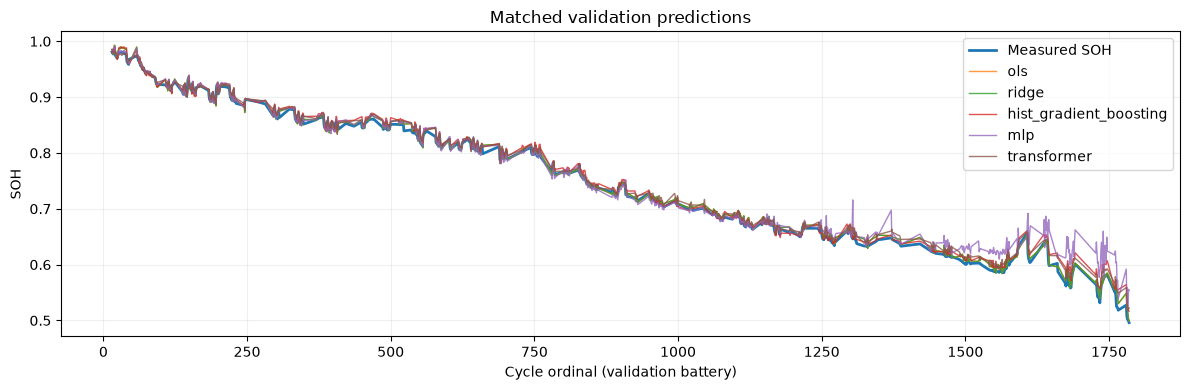

In [8]:
# Diagnostic plot of validation predictions, and per-battery breakdown.
fig,ax=plt.subplots(figsize=(12,4))
meta=windows['validation']['meta']; x=meta['cycle_ordinal'].to_numpy()
ax.plot(x,windows['validation']['y'],label='Measured SOH',lw=2)
for model_name in ['ols','ridge','xgboost' if HAVE_XGBOOST else 'hist_gradient_boosting','mlp','transformer']:
    path=OUTPUT_DIR/f'{model_name}_seed{SEEDS[0]}_validation_predictions.csv'
    if path.exists():
        d=pd.read_csv(path)
        ax.plot(d.cycle_ordinal,d.predicted_soh,lw=1,label=model_name,alpha=.8)
ax.set(xlabel='Cycle ordinal (validation battery)',ylabel='SOH',title='Matched validation predictions')
ax.grid(alpha=.2);ax.legend();fig.tight_layout()
fig.savefig(OUTPUT_DIR/'validation_predictions.png',dpi=160);plt.show()

# This split has one battery in our original protocol; still save programmatic detail.
per_cell=[]
for (name,seed),model in trained_models.items():
    for split in ['validation','test']:
        d=pd.read_csv(OUTPUT_DIR/f'{name}_seed{seed}_{split}_predictions.csv')
        for b,g in d.groupby('battery'):
            per_cell.append({'split':split,'model':name,'seed':seed,'battery':b,
                             'n':len(g),**evaluate_numbers(g.actual_soh,g.predicted_soh)})
per_cell=pd.DataFrame(per_cell)
per_cell.to_csv(OUTPUT_DIR/'per_battery_metrics.csv',index=False)

## 5 — Feature sufficiency: do we need all five indicators?

Test **CC alone**, **CC+CV**, **all five**, and **all except CC**. Because this is inexpensive screening, we use OLS, Ridge and XGBoost with identical sample rows. This is a **freshly fitted** model for each subset, not just zeroing features in a previously fitted model.

Do not use the test results to choose the feature subset. If CC alone performs similarly on validation, the next scientific task should be robustness, protocol shift or independent validation—not another complex network.

In [9]:
if RUN_FEATURE_ABLATIONS:
    feature_sets={
        'CC_only':['cc_duration_s'],
        'CC_CV':['cc_duration_s','cv_duration_s'],
        'without_CC':[f for f in FEATURES if f!='cc_duration_s'],
        'all_five':FEATURES[:]
    }
    ablation_rows=[]
    for setname,cols in feature_sets.items():
        idx=[FEATURES.index(f) for f in cols]
        tx=windows['train']['X'][:,-1,:][:,idx]
        for name in ['ols','ridge','xgboost' if HAVE_XGBOOST else 'hist_gradient_boosting']:
            seeds=(SEEDS[0],) if name in ('ols','ridge') else SEEDS
            for seed in seeds:
                model=(LinearRegression() if name=='ols' else Ridge(alpha=1.)) if name in ('ols','ridge') else build_tree(seed)
                model.fit(tx,windows['train']['y'])
                for split in ['validation','test']:
                    p=model.predict(windows[split]['X'][:,-1,:][:,idx])
                    ablation_rows.append({'feature_set':setname,'features':','.join(cols),
                          'model':name,'seed':seed,'split':split,'n_features':len(cols),
                          **evaluate_numbers(windows[split]['y'],p)})
    ablation_df=pd.DataFrame(ablation_rows)
    ablation_df.to_csv(OUTPUT_DIR/'feature_ablation_runs.csv',index=False)
    ablation_summary=(ablation_df.groupby(['split','model','feature_set']).agg(
           RMSE_mean=('RMSE','mean'),RMSE_std=('RMSE','std'),MAE_mean=('MAE','mean'))
           .reset_index())
    ablation_summary.to_csv(OUTPUT_DIR/'feature_ablation_summary.csv',index=False)
    print('Feature sufficiency — validation only:')
    display(ablation_summary.query('split=="validation"').sort_values(['model','RMSE_mean']).round(6))

Feature sufficiency — validation only:


,split,model,feature_set,RMSE_mean,RMSE_std,MAE_mean
14,validation,hist_gradient_boosting,all_five,0.009161,0.0,0.006797
13,validation,hist_gradient_boosting,CC_only,0.009161,0.0,0.007412
12,validation,hist_gradient_boosting,CC_CV,0.009591,0.0,0.007102
15,validation,hist_gradient_boosting,without_CC,0.033573,0.0,0.028082
16,validation,ols,CC_CV,0.006432,NaN,0.004876
18,validation,ols,all_five,0.006538,NaN,0.004978
17,validation,ols,CC_only,0.008760,NaN,0.006871
19,validation,ols,without_CC,0.027250,NaN,0.021972
20,validation,ridge,CC_CV,0.006458,NaN,0.004900
22,validation,ridge,all_five,0.006527,NaN,0.004967


## 6 — Missing-indicator robustness (evaluation-only stress test)

For a fixed trained model, replace **one or two entire feature channels** by their train-set mean (standardized zero), consistently across each input window. Every model receives the same synthetic missingness masks. A separate scenario removes CC duration for every sample.

This measures sensitivity to missing data, **not performance of a model trained to handle missingness**. No missing values are imputed from future observations. Real-world missingness patterns may be different.

In [10]:
if RUN_MISSINGNESS_STRESS:
    missing_rows=[]
    for split in ['validation','test']:
        X=windows[split]['X']
        for k_missing in [0,1,2]:
            # FIXED mask for each split/scenario shared across ALL models and seeds
            local_rng=np.random.default_rng(3100+k_missing+(0 if split=='validation' else 999))
            masked=X.copy()
            if k_missing:
                for i in range(len(masked)):
                    cols=local_rng.choice(len(FEATURES),size=k_missing,replace=False)
                    masked[i,:,cols]=0.  # equivalent to training mean imputation
            for (model_name,seed),model in trained_models.items():
                p=predict_torch(model,masked) if isinstance(model,nn.Module) else model.predict(masked[:,-1,:])
                missing_rows.append({'split':split,'scenario':f'random_{k_missing}_missing',
                       'model':model_name,'seed':seed,**evaluate_numbers(windows[split]['y'],p)})
        cc_missing=X.copy();cc_missing[:,:,FEATURES.index('cc_duration_s')]=0.
        for (model_name,seed),model in trained_models.items():
            p=predict_torch(model,cc_missing) if isinstance(model,nn.Module) else model.predict(cc_missing[:,-1,:])
            missing_rows.append({'split':split,'scenario':'CC_missing',
                'model':model_name,'seed':seed,**evaluate_numbers(windows[split]['y'],p)})
    missing_df=pd.DataFrame(missing_rows)
    missing_df.to_csv(OUTPUT_DIR/'missingness_runs.csv',index=False)
    missing_summary=(missing_df.groupby(['split','model','scenario']).agg(
            RMSE_mean=('RMSE','mean'),RMSE_std=('RMSE','std'),MAE_mean=('MAE','mean'))
            .reset_index())
    missing_summary.to_csv(OUTPUT_DIR/'missingness_summary.csv',index=False)
    print('Missingness stress — validation (compare to no missing):')
    display(missing_summary.query('split=="validation"').sort_values(['model','scenario']).round(6))

Missingness stress — validation (compare to no missing):


,split,model,scenario,RMSE_mean,RMSE_std,MAE_mean
20,validation,hist_gradient_boosting,CC_missing,0.133060,0.000000,0.116538
21,validation,hist_gradient_boosting,random_0_missing,0.009161,0.000000,0.006797
22,validation,hist_gradient_boosting,random_1_missing,0.060219,0.000000,0.030067
23,validation,hist_gradient_boosting,random_2_missing,0.080562,0.000000,0.050631
24,validation,mlp,CC_missing,0.147804,0.010484,0.129478
25,validation,mlp,random_0_missing,0.017943,0.002435,0.011257
26,validation,mlp,random_1_missing,0.069461,0.004249,0.037845
27,validation,mlp,random_2_missing,0.090808,0.001235,0.060969
28,validation,ols,CC_missing,0.159171,NaN,0.140024
29,validation,ols,random_0_missing,0.006538,NaN,0.004978


## 7 — Does the training-only 3-percentage-point filter help?

This audit retrains **only the cheap tabular models** on original versus filtered training cycles, always scoring the **same unchanged validation and test windows**. The train-only scaler is deliberately fixed to the filtered version for this sensitivity comparison. If outcomes change, it does not prove any removed label was erroneous.

In [11]:
if RUN_FILTER_SENSITIVITY:
    orig_windows=make_windows(original_train,mu,sigma)
    filt_rows=[]
    for variant,tr in [('original',orig_windows),('threshold_filtered',windows['train'])]:
        for model_name in ['ols','ridge','xgboost' if HAVE_XGBOOST else 'hist_gradient_boosting']:
            seeds=(SEEDS[0],) if model_name in ('ols','ridge') else SEEDS
            for seed in seeds:
                model=(LinearRegression() if model_name=='ols' else Ridge(alpha=1.)) if model_name in ('ols','ridge') else build_tree(seed)
                model.fit(tr['X'][:,-1,:],tr['y'])
                for split in ['validation','test']:
                    p=model.predict(windows[split]['X'][:,-1,:])
                    filt_rows.append({'training_set':variant,'train_windows':len(tr['y']),
                           'model':model_name,'seed':seed,'split':split,
                           **evaluate_numbers(windows[split]['y'],p)})
    filt_df=pd.DataFrame(filt_rows)
    filt_df.to_csv(OUTPUT_DIR/'filter_sensitivity_runs.csv',index=False)
    display(filt_df.groupby(['split','training_set','model']).RMSE.mean().unstack('training_set').round(6))

training_set                       original  threshold_filtered
split      model                                               
test       hist_gradient_boosting  0.013843            0.014299
           ols                     0.015814            0.016206
           ridge                   0.015743            0.016126
validation hist_gradient_boosting  0.008372            0.009161
           ols                     0.006286            0.006538
           ridge                   0.006279            0.006527

## 8 — Optional: Cross-cell diagnostic (LOBO)

Turn `RUN_LOBO=True` in configuration and rerun. Seven battery cells are available when combining the original CSV splits. For each held-out battery, a **different battery** is reserved as inner validation; transformations and filtering are fitted on the remaining cells only.

- It checks whether the simpler methods generalize across cells.
- Outer folds are **not** hyperparameter-tuning targets.
- Because we've already inspected CX2_38 and the other batteries in earlier studies, consider the results exploratory and seek an external test set for publication-level confirmation.
- Set `RUN_LOBO_TRANSFORMER=True` for a matched Transformer LOBO comparison. This is slower.
- Cross-cell filtering is rebuilt using the predeclared 3-percentage-point heuristic on **training cells only**. Held-out and inner-validation labels remain unchanged.

In [12]:
def filter_training_only(frame, threshold=.03):
    f=change_audit(frame,threshold=threshold)
    f['next_endpoint']=f.groupby('battery')['large_jump'].shift(-1,fill_value=False)
    return f.loc[~(f.large_jump | f.next_endpoint),frame.columns].copy()

if RUN_LOBO:
    all_cells=pd.concat([original_train,splits['validation'],splits['test']],ignore_index=True)
    all_cells=load_frame_like=all_cells.sort_values(['battery','cycle_ordinal']).reset_index(drop=True)
    batteries=sorted(all_cells.battery.unique())
    holdouts=batteries if LOBO_FOLDS=='full' else [b for b in ['CX2_16','CX2_35','CX2_38'] if b in batteries]
    fold_rows=[]
    for heldout in holdouts:
        remain=[b for b in batteries if b!=heldout]
        # Deterministic independent inner validation battery; never train on it.
        inner=remain[0]
        tr_df=all_cells[all_cells.battery.isin([b for b in remain if b!=inner])].copy()
        tr_df=filter_training_only(tr_df)
        va_df=all_cells[all_cells.battery==inner].copy()
        te_df=all_cells[all_cells.battery==heldout].copy()
        mm=tr_df[FEATURES].mean().to_numpy(np.float32)
        ss=tr_df[FEATURES].std(ddof=0).to_numpy(np.float32)
        ss=np.where(ss<1e-8,1.,ss)
        tr=make_windows(tr_df,mm,ss);va=make_windows(va_df,mm,ss);te=make_windows(te_df,mm,ss)
        families=['ols','ridge','xgboost' if HAVE_XGBOOST else 'hist_gradient_boosting']
        if RUN_LOBO_TRANSFORMER:families.append('transformer')
        for family in families:
            if family in ('ols','ridge'):
                model=(LinearRegression() if family=='ols' else Ridge(alpha=1.)).fit(tr['X'][:,-1,:],tr['y'])
                pred=model.predict(te['X'][:,-1,:])
            elif family in ('xgboost','hist_gradient_boosting'):
                model=build_tree(SEEDS[0]).fit(tr['X'][:,-1,:],tr['y'])
                pred=model.predict(te['X'][:,-1,:])
            else:
                model,_=train_neural('transformer',tr,va,SEEDS[0])
                pred=predict_torch(model,te['X'])
            fold_rows.append({'heldout':heldout,'inner_validation':inner,'model':family,
                        'n':len(te['y']),'training_windows':len(tr['y']),
                         **evaluate_numbers(te['y'],pred)})
        print('Finished outer holdout:',heldout,'| inner validation:',inner)
    lobo_df=pd.DataFrame(fold_rows)
    lobo_df.to_csv(OUTPUT_DIR/'lobo_exploratory_per_cell.csv',index=False)
    lobo_summary=lobo_df.groupby('model').agg(mean_fold_RMSE=('RMSE','mean'),
        std_fold_RMSE=('RMSE','std'),worst_fold_RMSE=('RMSE','max'),
        median_fold_RMSE=('RMSE','median'),n_folds=('heldout','nunique')).reset_index()
    lobo_summary.to_csv(OUTPUT_DIR/'lobo_exploratory_summary.csv',index=False)
    display(lobo_summary.sort_values('mean_fold_RMSE').round(5))

## 9 — Interpretation, files to share, and publication-oriented decision logic

**Do not infer a mechanistic cause from prediction error alone.** This notebook intentionally separates:

1. **Feature sufficiency:** If Ridge/XGBoost using CC alone matches the 5-feature Transformer, deep sequence modeling has little demonstrated benefit under this specific protocol.
2. **Missingness vulnerability:** If errors rise steeply when `cc_duration_s` is absent, partial-charge or missing-indicator SOH estimation is a promising practical question (but needs missingness-aware training and realistic data for validation).
3. **Cross-cell shift:** If LOBO errors differ significantly across cells, target protocol/chemistry/cell shifts rather than simply more parameters.
4. **Label reliability:** The measured SOH sawteeth are unresolved; never claim the threshold filter corrected them or that they represent physical recovery.

**Files to share:** `metrics_summary.csv`, `feature_ablation_summary.csv`, `missingness_summary.csv`, `filter_sensitivity_runs.csv`, and optional `lobo_exploratory_per_cell.csv`. Prediction CSVs are aligned by exact cycle, enabling paired comparisons and publication figures.

The best next research question should be selected from **repeatable, validation-supported problems**, not by finding the lowest number on previously inspected CX2_38.

In [13]:
# Compact output manifest and reproducibility configuration.
config={'data_dir':str(DATA_DIR),'train_csv':TRAIN_NAME,'features':FEATURES,
        'task':'current_cycle_SOH_estimation','seq_len':SEQ_LEN,'seeds':list(SEEDS),
        'epochs':EPOCHS,'patience':PATIENCE,'batch_size':BATCH_SIZE,'lr':LR,
        'xgb_estimators':XGB_ESTIMATORS,'torch_device':str(DEVICE),
        'normalization':'training-only mean/std','matched_windows':True,
        'run_feature_ablations':RUN_FEATURE_ABLATIONS,
        'run_missingness_stress':RUN_MISSINGNESS_STRESS,
        'run_filter_sensitivity':RUN_FILTER_SENSITIVITY,
        'run_lobo':RUN_LOBO,
        'warning':'original test battery CX2_38 has been inspected in earlier experiments'}
(OUTPUT_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2))
print('Saved result files to:',OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file() and p.suffix in ('.csv','.json','.png'):
        print(' ',p.name)

Saved result files to: C:\Projects\Battery_Soh\soh_research_gap_benchmark
  experiment_config.json
  feature_ablation_runs.csv
  feature_ablation_summary.csv
  filter_sensitivity_runs.csv
  hist_gradient_boosting_seed123_test_predictions.csv
  hist_gradient_boosting_seed123_validation_predictions.csv
  hist_gradient_boosting_seed2026_test_predictions.csv
  hist_gradient_boosting_seed2026_validation_predictions.csv
  hist_gradient_boosting_seed42_test_predictions.csv
  hist_gradient_boosting_seed42_validation_predictions.csv
  metrics_all_runs.csv
  metrics_summary.csv
  missingness_runs.csv
  missingness_summary.csv
  mlp_seed123_history.csv
  mlp_seed123_test_predictions.csv
  mlp_seed123_validation_predictions.csv
  mlp_seed2026_history.csv
  mlp_seed2026_test_predictions.csv
  mlp_seed2026_validation_predictions.csv
  mlp_seed42_history.csv
  mlp_seed42_test_predictions.csv
  mlp_seed42_validation_predictions.csv
  ols_seed42_test_predictions.csv
  ols_seed42_validation_predictions.